<center>
    <h2>Master 2</h2>
    <h5 style="margin-top: 5px">Sciences de l’Océan, de l’Atmosphère et du Climat</h5>
    <h1>TP - Système climatique</h1>
  <br>
    <strong>Contact:</strong> isaline.bossert@meteo.fr / romain.torres4@gmail.com

</center>


<div style="padding: 1rem; background-color: #d1ecf1; border: 1px solid #bee5eb; border-radius: 4px; margin: 1rem 0;">
  <strong>💡 Instructions</strong> 
    
Ce notebook est à <i>compléter</i> avec vos réponses aux questions posées et à <i>envoyer</i> par mail au plus tard <u>une semaine après la dernière séance de TP</u>. Merci de renommer le notebook pour y incorporer vos noms de famille (ex: TP-Climat-2026-Nom1_Nom2_Nom3.ipynb)
  - une attention particulière doit être donnée aux <b>figures</b> (clareté, titre, axes, légendes, etc..) 
  - les analyses portent sur vos <b>connaissances théoriques</b> en lien avec le cours "Système Climatique" (J. Cattiaux) sont attendues
  - la <b>curiosité scientifique</b> est bien sûre encouragée: même si les questions sont là pour aiguiller le TP, n'hésitez pas à demander des clarifications où d'éventuelles pistes d'analyses supplémentaires ;)
    

⚠️ Lors de la dernière séance, chaque groupe présentera son notebook (sujet + analyses effectuées):
  - durée max de 12 minutes de restitution qui doit être <b>claire</b> et <b>synthétique</b>. Il n'est pas nécessaire de créer un support de présentation particulier.
  - la restitution est suivie d'un <b>tour de questions</b> de la part des élèves puis des enseignantes pour vérifier les notions

<center>
        <h1>Sujet 3: Towards global climate stabilization, the use of emission-driven configurations </h1>
  <br>
    <strong>Main topics covered here:</strong>
    <br>
    Emission-driven vs. concentration-driven configuration
    <br>
    Net-positive, net-zero and net-negative emissions
    <br> Climate stabilization

</center>

## Introduction

The Earth's climate system is undergoing an unprecedented transformation driven by the continuous accumulation of greenhouse gases (GHGs) in the atmosphere resulting from human activities such as fossil fuel combustion, deforestation, and industrial activity. Since the pre-industrial era, the global mean surface air temperature (GMSAT) has risen by approximately 1.2°C and this lead to several negative impacts on ecosystem and human well-being.

In this context of climate change, climate mitigation policies were convened to address global warming. Among them, we can cite the Paris Agreement that was adopted in 2015 by signatory nations in the course of the United Nations Framework Convention on Climate Change (UNFCCC). This agreement motivates _"holding the increase in the global average temperature to well below 2°C above pre-industrial levels and to pursue efforts to limit the temperature increase to 1.5°C above pre-industrial levels"_. In addition, the Paris Agreement also developed the objective to _"achieve a balance between anthropogenic emissions by sources and removals by sinks of greenhouse gases"_. Having in mind these two objectives, we can consider that the Paris Agreement is concerned by net-zero and by targetting specific global warming levels: +1.5°C and +2.0°C above pre-industrial levels. 

Net-zero CO$_2$ emissions, often referred to as carbon neutrality, describe a state in which anthropogenic CO$_2$ emissions are balanced by anthropogenic CO$_2$ removals. This opposes to net-positive and net-negative emissions. See the following figure.

<img src="../figures/Ch4_net_zero.png" width="500" style="display: block;"/>
        
Unlike the other TP studied by the other groups, we'll start by learning how to design a precise experimental protocol to answer scientific questions. The aim of this TP is to understand how to build idealized simulation to study the effect of stopping CO$_2$-emissions. The protocol chosen is the TIPMIP protocol :

<b>TIPMIP protocol </b> [(Jones et al., 2026)](https://gmd.copernicus.org/articles/19/6941/2026/):

The TIPMIP protocol is composed of five types of simulations:
- 1 esm-piControl run (black)
- 1 net-positive ramp-up run (red)
- 2 net-zero runs (dark green)
- 2 net-negative ramp-down (blue)
- 1 net-zero run following a ramp-down phase (light green)

All of these simulations are shown as schematics in the figure below where the x-axis represents the model years and the y-axis represents the Global Mean Surface Temperature (GSAT).

<img src="../figures/gmd-19-6941-2026-avatar-web.png" width="500" style="display: block;"/>

The aim of this protocol is to build (in a coordinated manner between modelling group accross the world) a ramp-up run which branches from a piControl run. This ramp-up phase must create an increase in GSAT of about 0.2°C/decade. Next, CO$_2$ emissions are shut down when the ramp-up GSAT reaches specific Global Warming Levels (GWLs). 


To create such protocol we need to be able to stop emissions when wanted. This means that our model should be forced with CO$_2$-emissions. This is called the emission-driven (or e-driven) configuration. The configuration used by the other groups is a concentration-driven (or c-driven) one. Here is a figure to compare both configuration.

<img src="../figures/Ch3_framework_jones.png" width="500" style="display: block;"/>

<b>Steps followed in this TP: </b> 
* First you will calculate the required amount of emission to generate the ramp-up run (red above) of +0.2°C/decade : this will be done with the c-driven configuration.
* Then you will look at the ramp-up and net-zero simulations : this will be done with the e-driven configuration.
* Finally, you will analyse these results and put them in perspective.

<b>Technical aspect of this TP: </b> 
In particular, you will work with 2D data but also timeseries

## Load Python modules

Along this notebook, Python codes are used to analyse model outputs.
You first need to import and load required modules:

In [1]:
# manipulate file and data
import xarray as xr
import pandas as pd
import numpy as np
import regionmask

# statistics package
import statsmodels.api as sm
lowess = sm.nonparametric.lowess

# plotting
import matplotlib.pyplot as plt
import cartopy.crs as ccrs
from matplotlib.colors import ListedColormap
import cmocean

# useful functions
def find_nearest(array, value):
    array = np.asarray(array)
    idx = (np.abs(array - value)).argmin()
    return array[idx]

<a id="section-1"></a>
## 0. Technical aspects

In the world of climate science, we use different type of file format. Among them are "csv" files (extention ".csv") and "netcdf" files (extention ".nc"). The former are quite useful when working with timeseries while the latter are useful when working with 2D+time of 3D+time datasets.

Post-treatments of model outputs constitute a large part of the work of a climate scientist. In the following cell we open one csv file and one netcdf file, we invite you to look closely at these dataformat.

csv files are opened with the pandas python package (```import pandas as pd```). Netcdf files are opened with the xarray package (```import xarray as xr```). These two packages contain a lot of functions which enables simple to complex analysis. You can have a look at the [pandas](https://pandas.pydata.org/docs/) and [xarray](https://docs.xarray.dev/en/stable/index.html) documentation.


In [2]:
# load a csv file
da = xr.open_dataset("./../data/CNRM-ESM2-2/e-driven/tas_Ayr/tas_Ayr_CNRM-ESM2-1_02Kpd_r1i1p2f2_gr_185001-214912.nc")
# load a netcdf file
df = pd.read_csv("./../data/CNRM-ESM2-2/e-driven/dataframe/dataframe_02Kpd_timeseries_yearly_tas_Amon.csv")

#### Question 0.1: 
* Look at the variables ```da``` and ```df```


In [3]:
df

,year,esm-piControl,02Kpd,02Kpd-11,02Kpd-15,02Kpd-20,02Kpd-25,02Kpd-30,02Kpd-35,02Kpd-40,02Kpd-45,02Kpd-50,esm-up2p0-gwl2p0-50y-dn2p0,esm-up2p0-gwl4p0-50y-dn2p0,esm-up2p0-gwl4p0-50y-dn2p0-gwl2p0
0,1850,286.74274,286.70453,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
1,1851,286.67523,286.78897,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2,1852,286.70120,286.82294,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
3,1853,286.52563,286.79590,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
4,1854,286.67130,286.94452,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
630,2480,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,288.43488
631,2481,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,288.54883
632,2482,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,288.53378
633,2483,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,288.42795


In [4]:
da

<xarray.Dataset>
Dimensions:    (time: 300, bnds: 2, lon: 256, lat: 128)
Coordinates:
  * time       (time) datetime64[ns] 1850-07-01T06:00:00 ... 2149-07-01T06:00:00
  * lon        (lon) float64 0.0 1.406 2.812 4.219 ... 354.4 355.8 357.2 358.6
  * lat        (lat) float64 -88.93 -87.54 -86.14 -84.74 ... 86.14 87.54 88.93
    height     float64 ...
Dimensions without coordinates: bnds
Data variables:
    time_bnds  (time, bnds) datetime64[ns] ...
    tas        (time, lat, lon) float32 ...
Attributes: (12/54)
    CDI:                    Climate Data Interface version 2.0.4 (https://mpi...
    source:                 CNRM-ESM2-1 (2017):  aerosol: TACTIC_v2 atmos: Ar...
    institution:            CNRM (Centre National de Recherches Meteorologiqu...
    Conventions:            CF-1.7 CMIP-6.2
    name:                   /scratch/work/bosserti/CMIP6/DECK/AOESM_02Kpd_CM6...
    description:            Created by xios
    ...                     ...
    dr2xml_md5sum:          9a1fa5cac842f55652e42ad1d6b59c62
    xios_commit:            1442-shuffle
    nemo_gelato_commit:     49095b3accd5d4c_6524fe19b00467a
    arpege_minor_version:   6.3.2
    tracking_id:            hdl:21.14100/8fe1a6c2-7484-4940-9e56-defa49001bf2
    CDO:                    Climate Data Operators version 2.0.4 (https://mpi...

<a id="section-1"></a>
## 1.Building the ramp-up simulation



After discovering those two file formats, we can now begin with the scientific part of this TP. As mentioned in the introduction we plan here to work with idealized simulation composed of a esm-piControl, a ramp-up run and net-zero CO$_2$-emission runs. However, we need to begin somewhere :

**Goal of this section:** the final goal of this section is to calculate the yearly CO$_2$-emissions ($\Delta$E$_{1yr}$) required to build the ramp-up run of +0.2°C/decade. This can be achieved only by understanding what is the TCRE and how to calculate it.

**Climate sensitivity : What is the TCRE?**

Climate change studies use several climate metrics to measure the overall climate response to radiative forcings. Among these are the TCR (Transient Climate Response)
and the TCRE (Transient Climate Response to cumulative CO$_2$ Emissions) which both measure the climate sensitivity of a model.

The IPCC AR6 defines the TCR as "The surface temperature response for the hypothetical scenario in which atmospheric carbon dioxide (CO2) increases at 1% yr$^{–1}$
from pre-industrial to the time of a doubling of atmospheric CO2 concentration (year 70)", whereas the TCRE is defined as "The transient surface temperature change per unit cumulative carbon dioxide (CO2) emissions, usually 1000 GtC. TCRE combines both information on the airborne fraction of cumulative CO2 emissions (the fraction of
the total CO2 emitted that remains in the atmosphere, which is determined by carbon cycle processes) and on the transient climate response (TCR)" 

The distinctive feature of TCRE lies on its near-linear relationship between temperature change (unit: °C) and cumulative carbon emissions (unit: GtC). The TCRE is therfore expressed in °C.GtC−1.
The following Figure displays this linear relationship for a set of 11 climate models in panel (b). In addition, this relationship is pathway independent as shown in panel (a) for both observations and various SSP scenarios.
        
<img src="../figures/Ch4_TCRE_figures.png" width="700" style="display: block;"/>
        
**Figure –** The TCRE is near linear and pathway independant. Panel (a) illustrates that the TCRE remains almost unchanged with different shared socio-economic
pathways. Panel (b) highlights the near-linear relationship between temperature change and cumulative carbon emission for a set of 11 climate models. Reference: Panel (a)
is reproduced from IPCC (2021b). Panel (b) is reproduced from Matthews and Caldeira (2008).

The TCRE is the key metric to link increment in global surface air temperature ($\Delta$GSAT) and increment in CO$_2$-emission ($\Delta$E$_{c,cum}$). Once it is calculated for our model we can twist it around to infer the amount of CO$_2$-emissions required to generate a yearly increase in global temperature of 0.2°C/decade. 

This metric is calculated using the method of [(Arora et al., 2020)](https://bg.copernicus.org/articles/17/4173/2020/). It is derived from two concentration-driven simulations being the _piControl_ and _1pctCO2_. The _piControl_ provides a reference to evaluate the increment in both warming and atmospheric CO$_2$ concentration in the _1pctCO2_ run.

The TCRE is defined as the ratio between the Global mean Surface Air Temperature increase ($\Delta$GSAT) and the total cumulative CO$_2$-emissions ($\Delta$E$_{cum}$) at the time where the CO$_2$ concentration doubles in _1pctCO2_ compared to the _piControl_ levels.

The following questions guide you to the calculation of the TCRE and ultimately to $\Delta$E$_{c,cum}$. Follow these steps carefully :

* **Step1 :** Calculate the Global mean Surface Air Temperature (GSAT) anomaly: $\Delta$GSAT (°C)
* **Step2 :** Calculate the compatible CO$_2$-emissions (i.e. the CO$_2$-emissions required to maintain the atmospheric CO$_2$ concentration to the level prescribed in the _1pctCO2_ simulation): E$_c$ or $\Delta$E$_c$ when expressed relative to the piControl baseline (EgC)
    * First, calculate the ocean-atmosphere carbon fluxes : GtC/yr
    * Second, calculate the land-atmosphere carbon fluxes : GtC/yr
    * Third, calculate the atmospheric growth rate (convert the prescribed CO$_2$ concentration in a CO$_2 flux called AGR): ppm/yr or GtC/yr
    * Finally, calculate the total carbon compatible emission as follows :
<img src="../figures/Emission_compatible.png" width="500" style="display: block;"/>

* **Step3 :** Calculate the cumulative compatible CO$_2$-emissions: E$_{c,cum}$ or $\Delta$E$_{c,cum}$ in GtC/yr

In [10]:
# load csv files for the 1pctCO2 and picontrol simulation for different variables
df_tas_cd = pd.read_csv("./../data/CNRM-ESM2-2/c-driven/dataframe_tas_Ayr_c-driven.csv")
df_nbp_cd = pd.read_csv("./../data/CNRM-ESM2-2/c-driven/dataframe_nbp_Lyr_c-driven.csv")
df_fgco2_cd = pd.read_csv("./../data/CNRM-ESM2-2/c-driven/dataframe_fgco2_Oyr_c-driven.csv")

GHG = pd.read_csv("./../data/CNRM-ESM2-2/c-driven/GHG_1pctCO2.csv", sep=" ")

#### Question 1.1: 

In the previous cell we loaded three dataframes (```df_tas_cd```, ```df_nbp_cd``` and ```df_fgco2_cd```). They gather data of three different variables averaged or integrated globally.
* df refers to "dataframe"
* cd refers to concentration-driven or c-driven
* tas, nbp and fgco2 are more clueless. These are reference name for variables in the climate community. Check on the [CMIP6](
https://clipc-services.ceda.ac.uk/dreq/mipVars.html) website what they refer to and write it down. 
* Discuss the choice of word here "averaged" vs. "integrated".

#### Question 1.2: 

* Plot the GSAT for the _piControl_ run and for the _1pctCO2_ run. 
* Infer the GSAT anomaly ($\Delta$GSAT) relative to the _piControl_ baseline.

In [11]:
# extract variables
year = df_tas_cd["year"]
GSAT = df_tas_cd["1pctCO2"]
GSAT_pi = df_tas_cd["piControl"]

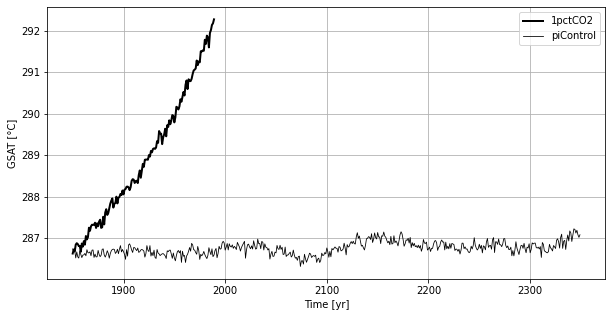

In [12]:
fig, ax = plt.subplots(1, 1, figsize=(10, 5))
ax.plot(year, GSAT, color="k", lw=2, label="1pctCO2")
ax.plot(year, GSAT_pi, color="k", lw=0.8, label="piControl")

# aesthetic
ax.set_xlabel("Time [yr]")
ax.set_ylabel("GSAT [°C]")
ax.legend()
ax.grid()

In [13]:
# calculate the GSAT anomaly relative to piControl
D_GSAT = GSAT - np.mean(GSAT_pi)

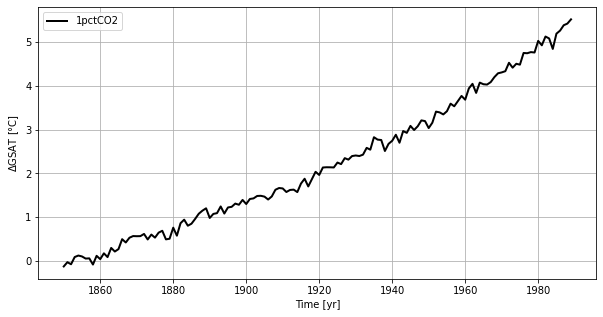

In [14]:
fig, ax = plt.subplots(1, 1, figsize=(10, 5))
ax.plot(df_tas_cd["year"], D_GSAT, color="k", lw=2, label="1pctCO2")

# aesthetic
ax.set_xlabel("Time [yr]")
ax.set_ylabel(r"$\Delta$GSAT [°C]")
ax.legend()
ax.grid()

#### Question 1.3: 

* Plot the ocean-atmosphere carbon fluxes for _1pctCO2_ and _piControl_
* Plot the land-atmosphere carbon fluxes (nb) for _1pctCO2_ and _piControl_
* Combine these two fluxes to get the total carbon fluxes. Discuss their evolution and sign.

In [15]:
# extract variables
year = df_fgco2_cd["year"]
fgco2 = df_fgco2_cd["1pctCO2"]
fgco2_pi = df_fgco2_cd["piControl"]

nbp = df_nbp_cd["1pctCO2"]
nbp_pi = df_nbp_cd["piControl"]

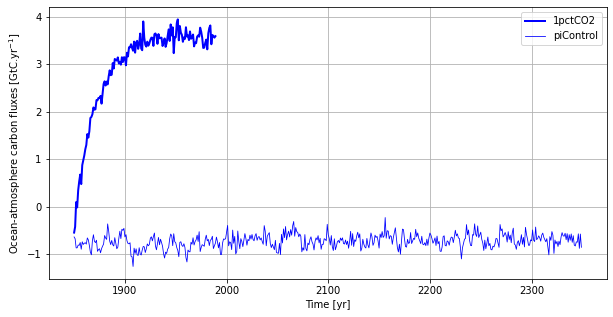

In [16]:
fig, ax = plt.subplots(1, 1, figsize=(10, 5))
ax.plot(year, fgco2, color="b", lw=2, label="1pctCO2")
ax.plot(year, fgco2_pi, color="b", lw=0.8, label="piControl")

# aesthetic
ax.set_xlabel("Time [yr]")
ax.set_ylabel("Ocean-atmosphere carbon fluxes [GtC.yr$^{-1}$]")
ax.legend()
ax.grid()

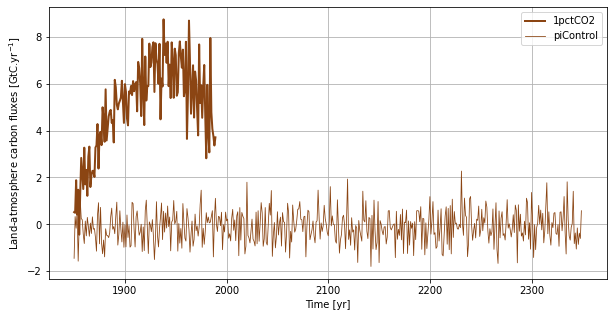

In [17]:
fig, ax = plt.subplots(1, 1, figsize=(10, 5))

ax.plot(year, nbp, color="saddlebrown", lw=2, label="1pctCO2")
ax.plot(year, nbp_pi, color="saddlebrown", lw=0.8, label="piControl")

# aesthetic
ax.set_xlabel("Time [yr]")
ax.set_ylabel("Land-atmosphere carbon fluxes [GtC.yr$^{-1}$]")
ax.legend()
ax.grid()

In [18]:
# calculate the total carbon fluxes
carbon_fluxes = nbp + fgco2
carbon_fluxes_pi = nbp_pi + fgco2_pi

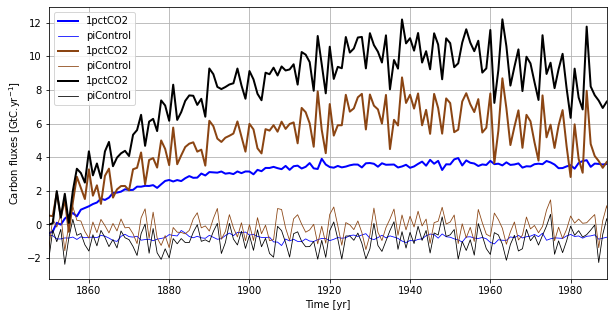

In [19]:
fig, ax = plt.subplots(1, 1, figsize=(10, 5))
ax.plot(year, fgco2, color="b", lw=2, label="1pctCO2")
ax.plot(year, fgco2_pi, color="b", lw=0.8, label="piControl")

ax.plot(year, nbp, color="saddlebrown", lw=2, label="1pctCO2")
ax.plot(year, nbp_pi, color="saddlebrown", lw=0.8, label="piControl")

ax.plot(year, carbon_fluxes, color="k", lw=2, label="1pctCO2")
ax.plot(year, carbon_fluxes_pi, color="k", lw=0.8, label="piControl")



# aesthetic
ax.set_xlabel("Time [yr]")
ax.set_ylabel("Carbon fluxes [GtC.yr$^{-1}$]")
ax.set_xlim([1850,1989])
ax.legend()
ax.grid()

#### Question 1.4: 

* Plot the prescribed CO$_2$ forcings in the _1pctCO2_ simulation and find the year when it doubles. 

 **Help:** you can use the python function find_nearest.

In [23]:
# extract variables
year = GHG["year"].values
CO2 = GHG["CO2"].values[0:len(year)]

In [24]:
# year when CO2 doubles
iyear_2CO2 = np.where(CO2==find_nearest(CO2, 2*CO2[0]))[0][0]
year_2CO2 = year[iyear_2CO2]

Text(0.5, 0, 'Time [yr]')

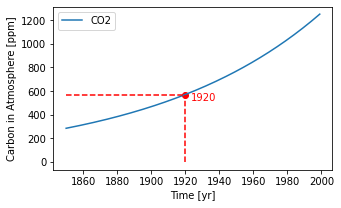

In [25]:
fig, ax = plt.subplots(1,1, figsize=(5,3))

ax.plot(year, CO2, label="CO2")

ax.hlines(2*CO2[0],year[0], year_2CO2, ls="--", color="r")
ax.vlines(year_2CO2,-5, 2*CO2[0], ls="--", color="r")
ax.scatter(year_2CO2, 2*CO2[0], c="r")
ax.text(year_2CO2+3, 2*CO2[0]-50, s=str(year_2CO2), c="r")

# aestetic
ax.legend()
ax.set_ylabel(r"Carbon in Atmosphere [ppm]")
ax.set_xlabel(r"Time [yr]")

#### Question 1.5: 

In a concentration-driven model, the atmospheric CO$_2$ concentration is supplied to the model as an input (_i.e._ forcing). Then, the model simulates the land and ocean carbon cycles. Carbon downward or upward fluxes, relative to the atmospheric reservoir, are thus activated (_e.g._ photosynthesis, oceanic physical carbon pump, outgassing). You looked at these sinks of carbon previously in that section.

In a concentration-driven simulation, the model does not "know" the CO$_2$-emissions: atmospheric CO$_2$ is prescribed. The emissions are therefore diagnosed a posteriori: we take what is needed to make the atmosphere CO$_2$ content grow.
Without the growth rate, we would only know the portion taken up by the sinks, not the total emitted. **It is the piece that links the prescribed concentration pathway to the anthropogenic emissions required to sustain it.**

Fluxes in and out of the atmosphere can be aggregated globally to estimate the compatible emissions. Compatible emissions are the quantity of emissions required to compensate the carbon sinks in order to maintain the atmospheric CO2 to the prescribed levels. This quantity is a diagnostic of the model output meaning that it is evaluated a posteriori. Compatible emissions (E$_c$) can be calculated as described in the following Equation. AGR (Atmospheric Growth Rate) represents the time derivative of the prescribed CO2, and nbp and fgco2 represent the net carbon fluxes towards the biosphere or the ocean respectively.

Overall, we need to close the budget in CO$_2$.


<img src="../figures/Emission_compatible.png" width="500" style="display: block;"/>



* Calculate and plot the AGR in GtC.yr$^{-1}$.

**Help:** Think about the conversion ratio from ppm to GtC.

In [26]:
# calculate the atmospheric growth rate (AGR)
# AGR en ppm.y-1 
AGR = np.zeros(len(CO2))
AGR[1:] = [CO2[i]-CO2[i-1] for i in range(1, len(CO2))]
# AGR en GtC.Y-1 : conversion 2.12 GtC.ppm-1
AGR = 2.12*np.array(AGR)

Text(0.5, 0, 'Time [yr]')

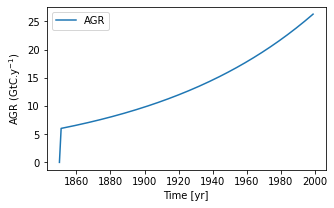

In [27]:
fig, ax = plt.subplots(1,1, figsize=(5,3))

ax.plot(year, AGR, label=("AGR"))

# aestetic
ax.legend()
ax.set_ylabel(r"AGR (GtC.y$^{-1}$)")
ax.set_xlabel("Time [yr]")

#### Question 1.6: 

* Calculate and plot the compatible CO$_2$-emissions (E$_c$) relative to the piControl ($\Delta$E$_c$).

<img src="../figures/emission_compatible.png" width="500" style="display: block;"/>

* Calculate the cumulative compatible CO$_2$-emissions ($\Delta$E$_{c,cum}$).
        


In [31]:
D_Ec = AGR\
      + (nbp[0:150] - nbp_pi.mean())\
      + (fgco2[0:150] - fgco2_pi.mean())

Text(0, 0.5, '$\\Delta$ Emission compatible (GtC.y$^{-1}$)')

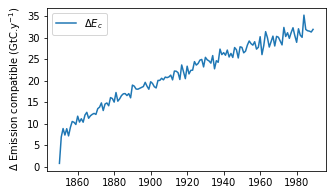

In [32]:
fig, ax = plt.subplots(1,1, figsize=(5,3))

ax.plot(year, D_Ec, label=(r"$\Delta E_c$"))

# aestetic
ax.legend()
ax.set_ylabel(r"$\Delta$ Emission compatible (GtC.y$^{-1}$)")

In [33]:
# GtC.y-1 * y = GtC
D_Eccum = np.cumsum(D_Ec)

Text(0, 0.5, 'Cumulative Emission (GtC)')

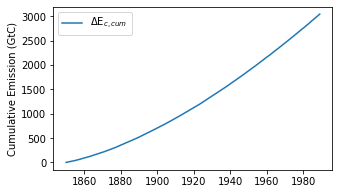

In [39]:
fig, ax = plt.subplots(1,1, figsize=(5,3))

ax.plot(year, D_Eccum, label=(r"$\Delta$E$_{c,cum}$"))

# aestetic
ax.legend()
ax.set_ylabel(r"Cumulative Emission (GtC)")

#### Question 1.7: 

* Calculate the TCRE.

[(Gillett et al., 2013)](https://journals.ametsoc.org/view/journals/clim/26/18/jcli-d-12-00476.1.xml) : "TCRE (i.e., a straight line passing through the origin and the 20-yr-mean temperature anomaly and cumulative emissions centered on year 70), corresponding to doubled preindustrial CO2 concentration and approximately 1 EgC cumulative emissions."

__Help 1:__ This metric is generally expressed as °C/EgC. So make sure both $\Delta$GSAT and $\Delta$E$_{c,cum}$ are expressed in the right unit.

__Help 2:__ you can plot $\Delta$GSAT against $\Delta$E$_{c,cum}$ to visualize the proportionality between the two variables. Then, you can identify the 20-years period and calculate the TCRE over it.

In [34]:
# °C/GtC / 1000 = °C/EgC
conversion_D_Eccum = D_Eccum/1000

Text(0.5, 0, '$\\Delta$E$_{c,cum}$ [EgC]')

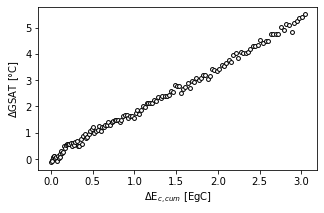

In [35]:
fig, ax = plt.subplots(1,1, figsize=(5,3))

ax.scatter(conversion_D_Eccum, D_GSAT[0:150], s=15, facecolor="w", edgecolor="k", alpha=1)
# ax.scatter(conversion_D_Eccum[61:81], D_GSAT[61:81], facecolor="w", edgecolor="r", s=50, alpha=1)

# aestetic
ax.set_ylabel("$\Delta$GSAT [°C]")
ax.set_xlabel("$\Delta$E$_{c,cum}$ [EgC]")

In [36]:
# Calculate the index of the 20 years period 
start_year = iyear_2CO2-9
end_year = iyear_2CO2+10

Text(0.5, 0, '$\\Delta$E$_{c,cum}$ [EgC]')

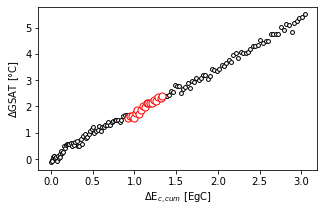

In [37]:
fig, ax = plt.subplots(1,1, figsize=(5,3))

ax.scatter(conversion_D_Eccum, D_GSAT[0:150], s=15, facecolor="w", edgecolor="k", alpha=1)
ax.scatter(conversion_D_Eccum[start_year:end_year], D_GSAT[start_year:end_year], facecolor="w", edgecolor="r", s=50, alpha=1)

# aestetic
ax.set_ylabel("$\Delta$GSAT [°C]")
ax.set_xlabel("$\Delta$E$_{c,cum}$ [EgC]")

In [44]:
np.mean(D_GSAT[start_year:end_year]) # °C

1.981397386315872

In [46]:
np.mean(conversion_D_Eccum[start_year:end_year]) # EgC

1.12718843207527

In [47]:
TCRE = np.mean(D_GSAT[start_year:end_year])/np.mean(conversion_D_Eccum[start_year:end_year]) 

In [51]:
TCRE # °C/EgC

1.757822676256458

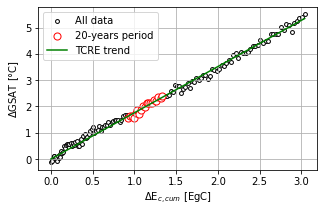

In [65]:
fig, ax = plt.subplots(1,1, figsize=(5,3))

ax.scatter(conversion_D_Eccum, D_GSAT[0:150], s=15, facecolor="w", edgecolor="k", alpha=1, label="All data")
ax.scatter(conversion_D_Eccum[start_year:end_year], D_GSAT[start_year:end_year], facecolor="w", edgecolor="r", s=50, alpha=1, label="20-years period")

ax.plot(conversion_D_Eccum, conversion_D_Eccum*TCRE, color="green", label="TCRE trend")

# aestetic
ax.set_ylabel("$\Delta$GSAT [°C]")
ax.set_xlabel("$\Delta$E$_{c,cum}$ [EgC]")
ax.grid()
ax.legend()

#### Question 1.8: 

* Calculate the CO$_2$-emission forcing necesseray to build a +0.2°C/decade simulation. $\Delta$E$_{1yr}$. Express it in GtC

__Help:__ We mentioned that we want an idealized +0.2 °C.decade$^{−1}$ ramp-up simulation. This also corresponds to a +0.02 °C increment per
year. Having calculated our TCRE we can now infer the CO2-emissions required for our experimental design.


In [103]:
D_E1yr = +0.02/TCRE  # °C/(°C/EgC) = EgC

In [104]:
D_E1yr = D_E1yr * 1000  # EgC --> GtC

In [105]:
D_E1yr

11.377711910391863

#### Question 1.9: 

* Summarize what was done in this section.

<a id="section-1"></a>
## 2. Create a forcing file to put in our model

In this section, we want to create a netcdf file to put as input to our model. That way you can manipulate xarray and netcdf data.

#### Question 2.1: 

Models are given emission on a monthly basis. Calculate the monthly emission in alignment with $\Delta$E$_{1yr}$ and distribute it homogeneously over the globe. It should be expressed in kgC.m$^{-2}$.s$^{-1}$.

* Create a data array with xarray to put as input in our model.

**Help:** the model grid is given in ``./../data/CNRM-ESM2-2/e-driven/tas_Ayr/areacella_CNRM-ESM2-1.nc``

In [106]:
# load grid array
areacella = xr.open_dataset("./../data/CNRM-ESM2-2/e-driven/tas_Ayr/areacella_CNRM-ESM2-1.nc")

In [123]:
# calculate total area
total_area = float(areacella.sum(["lat", "lon"])["cell_area"].values)

In [124]:
total_area = 510067027738624.0

In [125]:
D_E1yr_convert = D_E1yr*(10**12) # GtC/yr --> kgC/yr

In [126]:
D_E1yr_convert

11377711910391.863

In [127]:
D_E1yr_convert = D_E1yr_convert/(365*24*3600) # kgC/yr --> kgC.s-1

In [128]:
D_E1yr_convert

360784.8779297268

In [129]:
D_E1yr_convert_distributed = D_E1yr_convert/total_area # kgC.m-2.s-1

In [130]:
D_E1yr_convert_distributed_monthly = D_E1yr_convert_distributed/12

In [149]:
D_E1yr_convert_distributed_monthly

5.894403060601372e-11

<a id="section-1"></a>
## 2. Global scale metrics behaviour - Getting started with climate data

Perfect, you now have your CO$_2$-emission forcing field. Since running the simulation can take a couple of month, these were already run and we give you only the outputs so that you can work with them.

In this section, we will first analyse the behaviour of global scale metrics following emission cessation : GMCO2 (Global Mean Atmospheric CO2 concentration) and GSAT

We now enter the world of model driven by emission: emission-driven configuration or e-driven. The pre-industrial control simulation is called here _esm-piControl_.

In [150]:
# load variables
df_GSAT = pd.read_csv("./../data/CNRM-ESM2-2/e-driven/dataframe/dataframe_02Kpd_timeseries_yearly_tas_Amon.csv")
df_CO2 = pd.read_csv("./../data/CNRM-ESM2-2/e-driven/dataframe/dataframe_02Kpd_timeseries_yearly_co2s.csv")

#### Question 2.1: 

First, lets investigate the behaviour of GSAT and GMCO2 in the esm-picontrol run

* Plot these two variables 

Text(0.5, 1.0, 'b. GMCO2 in esm-piControl')

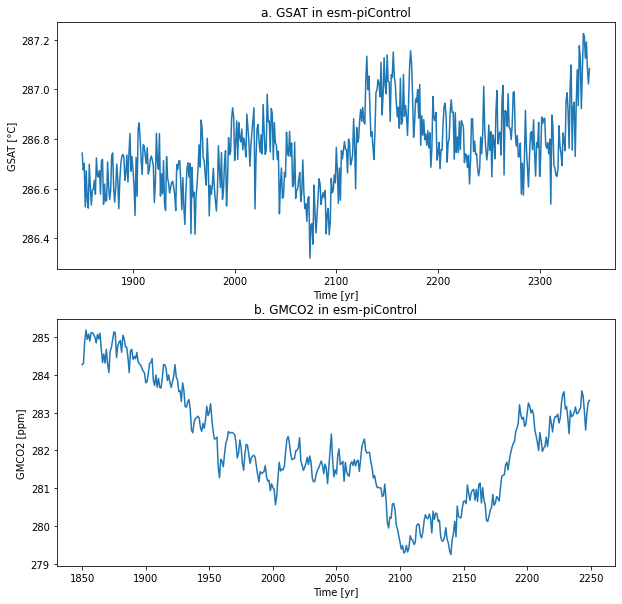

In [151]:
fig, axes = plt.subplots(2, 1, figsize=(10, 10))

axes[0].plot(df_GSAT["year"], df_GSAT["esm-piControl"])
axes[1].plot(df_CO2["year"], df_CO2["esm-piControl"])

axes[0].set_xlabel("Time [yr]")
axes[0].set_ylabel("GSAT [°C]")
axes[1].set_xlabel("Time [yr]")
axes[1].set_ylabel("GMCO2 [ppm]")

axes[0].set_title("a. GSAT in esm-piControl")
axes[1].set_title("b. GMCO2 in esm-piControl")

#### Question 2.2: 

In climate science, when working with model outputs, we often work with anomalies with respect to a baseline and not with absolute data. This enables scientists to compare models that differ slightly.

* _Plot GMCO2 and GSAT in anomalies_
* _Discuss the behaviour of the model in these esm-piControl runs. Calcule the temporal mean and the trend._

Text(0.5, 1.0, 'b. GMCO2 in esm-piControl')

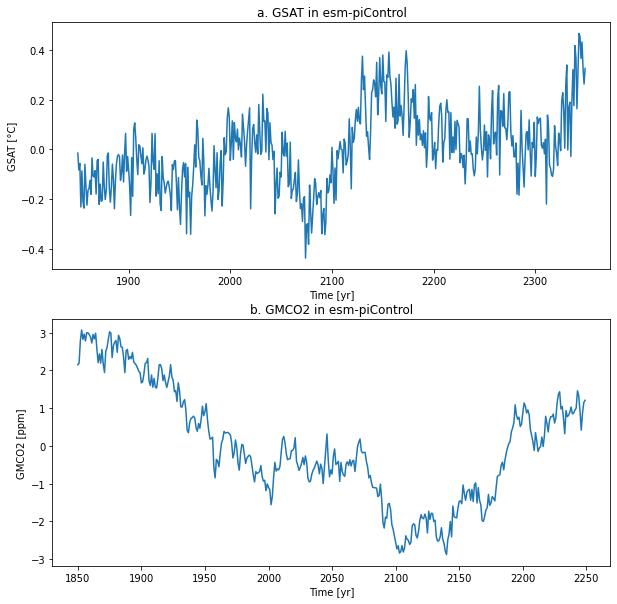

In [152]:
fig, axes = plt.subplots(2, 1, figsize=(10, 10))

axes[0].plot(df_GSAT["year"], df_GSAT["esm-piControl"]-df_GSAT["esm-piControl"].mean())
axes[1].plot(df_CO2["year"], df_CO2["esm-piControl"]-df_CO2["esm-piControl"].mean())

axes[0].set_xlabel("Time [yr]")
axes[0].set_ylabel("GSAT [°C]")
axes[1].set_xlabel("Time [yr]")
axes[1].set_ylabel("GMCO2 [ppm]")

axes[0].set_title("a. GSAT in esm-piControl")
axes[1].set_title("b. GMCO2 in esm-piControl")

#### Question 2.3: 

Now we will add on top of the _esm-piControl_ another simulation: 02Kpd. This is the ramp-up run for which you calculated the forcing in the previous sections.

* _Plot GSAT and GMCO2 of the ramp-up run on top of the piControl run"_
* _Discuss the behaviour of both variables_

Text(0.5, 1.0, 'b. GMCO2 in esm-piControl')

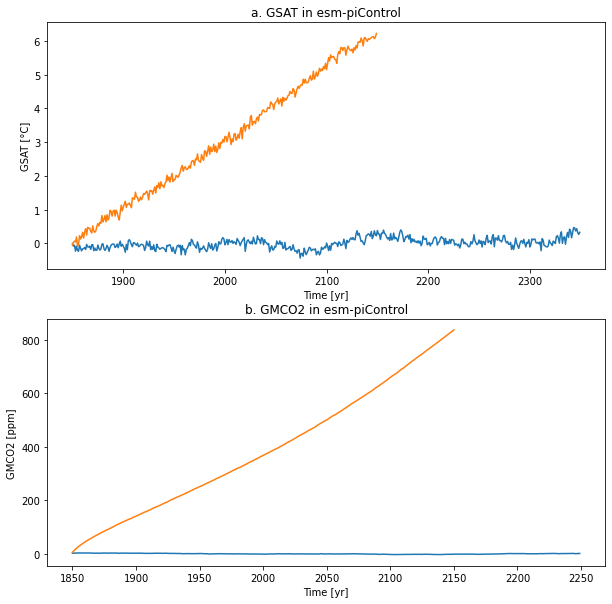

In [160]:
fig, axes = plt.subplots(2, 1, figsize=(10, 10))

ref_CO2 = df_CO2["esm-piControl"].mean()
ref_GSAT = df_GSAT["esm-piControl"].mean()

axes[0].plot(df_GSAT["year"], df_GSAT["esm-piControl"]-ref_GSAT)
axes[1].plot(df_CO2["year"], df_CO2["esm-piControl"]-ref_CO2)

axes[0].plot(df_GSAT["year"], df_GSAT["02Kpd"]-ref_GSAT)
axes[1].plot(df_CO2["year"], df_CO2["02Kpd"]-ref_CO2)

axes[0].set_xlabel("Time [yr]")
axes[0].set_ylabel("GSAT [°C]")
axes[1].set_xlabel("Time [yr]")
axes[1].set_ylabel("GMCO2 [ppm]")

axes[0].set_title("a. GSAT in esm-piControl")
axes[1].set_title("b. GMCO2 in esm-piControl")

#### Question 2.4: 

Lets move on to the next simulation 02Kpd-11.

* _Plot GSAT and GMCO2 for simulation 02Kpd-11_
* _According to you what changes were made in the forcings to obtain this new simulation ?_
* _Discuss the behaviour or GSAT and GMCO2_.

Text(0.5, 1.0, 'b. GMCO2 in esm-piControl')

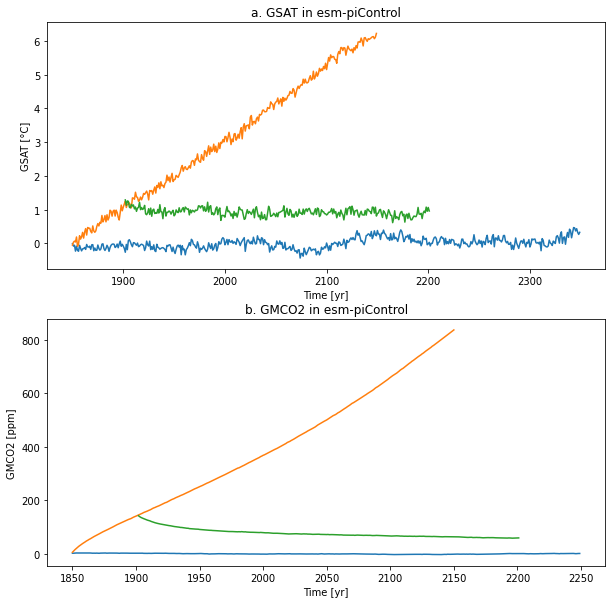

In [163]:
fig, axes = plt.subplots(2, 1, figsize=(10, 10))

ref_CO2 = df_CO2["esm-piControl"].mean()
ref_GSAT = df_GSAT["esm-piControl"].mean()

axes[0].plot(df_GSAT["year"], df_GSAT["esm-piControl"]-ref_GSAT)
axes[1].plot(df_CO2["year"], df_CO2["esm-piControl"]-ref_CO2)

axes[0].plot(df_GSAT["year"], df_GSAT["02Kpd"]-ref_GSAT)
axes[1].plot(df_CO2["year"], df_CO2["02Kpd"]-ref_CO2)

axes[0].plot(df_GSAT["year"], df_GSAT["02Kpd-11"]-ref_GSAT)
axes[1].plot(df_CO2["year"], df_CO2["02Kpd-11"]-ref_CO2)


axes[0].set_xlabel("Time [yr]")
axes[0].set_ylabel("GSAT [°C]")
axes[1].set_xlabel("Time [yr]")
axes[1].set_ylabel("GMCO2 [ppm]")

axes[0].set_title("a. GSAT in esm-piControl")
axes[1].set_title("b. GMCO2 in esm-piControl")

#### Question 2.5: 

Okay, now we will plot a lot more _02Kpd-XX_ simulations.
    
* _Plot the rest of the simulations in the dataframes df_CO2 and df_GSAT. Use a for-loop and use meaningful colors for each of the runs._
* _Characterize the behaviour of GSAT_

esm-piControl
02Kpd
02Kpd-11
02Kpd-15
02Kpd-20
02Kpd-25
02Kpd-30
02Kpd-35
02Kpd-40
02Kpd-45
02Kpd-50


Text(0.5, 1.0, 'b. GMCO2 in piControl')

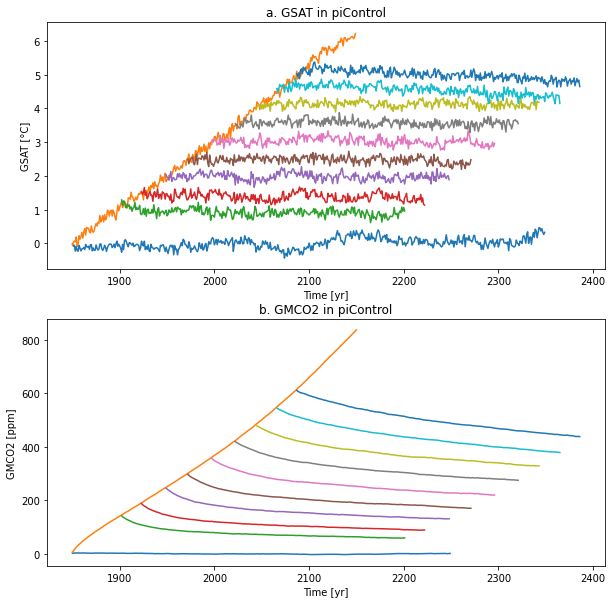

In [168]:
fig, axes = plt.subplots(2, 1, figsize=(10, 10))

ref_CO2 = df_CO2["esm-piControl"].mean()
ref_GSAT = df_GSAT["esm-piControl"].mean()

columns = df_GSAT.keys()
for i in range(1,12):
    print(columns[i])
    axes[0].plot(df_GSAT["year"], df_GSAT[columns[i]]-ref_GSAT)
    axes[1].plot(df_CO2["year"], df_CO2[columns[i]]-ref_CO2)

axes[0].set_xlabel("Time [yr]")
axes[0].set_ylabel("GSAT [°C]")
axes[1].set_xlabel("Time [yr]")
axes[1].set_ylabel("GMCO2 [ppm]")

axes[0].set_title("a. GSAT in piControl")
axes[1].set_title("b. GMCO2 in piControl")

#### Question 2.6: technical question

Up to now, we have given you the timeseries pre-processed. Try to calculate GSAT with a netcdf file.

* _Plot the 02Kpd-11 and 02KPd run using netcdf files._
* _Do you find the same result?_

**Help1 :** Netcdf files for temperature are stored in ```./../data/CNRM-ESM2-2/e-driven/tas_Ayr/```.

**Help2 :** Use the xarray .mean() function

In [174]:
ym_tas = xr.open_dataset("./../data/CNRM-ESM2-2/e-driven/tas_Ayr/tas_Ayr_CNRM-ESM2-1_02Kpd_r1i1p2f2_gr_185001-214912.nc")
ym_tas_11 = xr.open_dataset("./../data/CNRM-ESM2-2/e-driven/tas_Ayr/tas_Ayr_CNRM-ESM2-1_02Kpd-11_r1i1p2f2_gr_190201-220112.nc")

Text(0, 0.5, 'GSAT [°C]')

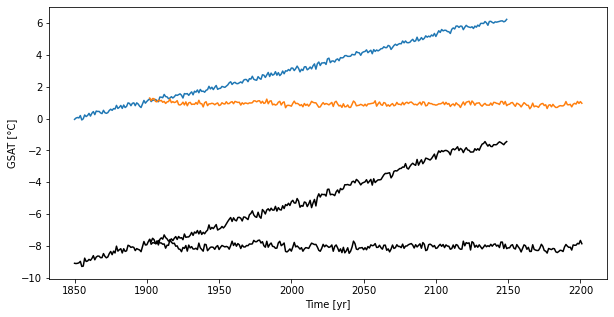

In [175]:
fig, ax = plt.subplots(1, 1, figsize=(10, 5))

ref_CO2 = df_CO2["esm-piControl"].mean()
ref_GSAT = df_GSAT["esm-piControl"].mean()

ax.plot(df_GSAT["year"], df_GSAT["02Kpd"]-ref_GSAT)
ax.plot(df_GSAT["year"], df_GSAT["02Kpd-11"]-ref_GSAT)

ax.plot(ym_tas_11["time"].dt.year, ym_tas_11["tas"].mean(["lat", "lon"])-ref_GSAT, color="k")
ax.plot(ym_tas["time"].dt.year, ym_tas["tas"].mean(["lat", "lon"])-ref_GSAT, color="k")

ax.set_xlabel("Time [yr]")
ax.set_ylabel("GSAT [°C]")

#### Question 2.7: technical question

Calculating a global mean with a netcdf file is not so straightforward. Ideed, you have to take into account the latitude/longitude grid. This grid is stored in the file _areacella_.
* _Plot the tas map averaged over a certain time period as well as the aeracella map. From that infer why your calculation was underestimating the GSAT in the previous question_
* _With that in mind try to recalculate GSAT by using a weighted-mean rather than a simple mean._

__Help:__ Maps can be plotted as follows : 

```
fig, ax = plt.subplots(1, 1, figsize=(10, 5), subplot_kw=dict(projection=ccrs.Robinson(0)))

da.plot(ax=...,
        x=...,
        y=...,
        transform=ccrs.PlateCarree() # This line explains that the data in the dataset are expressed using a regular grid
        ) 
```

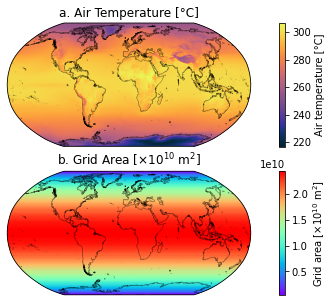

In [178]:
fig, axes = plt.subplots(2, 1, figsize=(10, 5), subplot_kw=dict(projection=ccrs.Robinson(0)))

im1 = ym_tas_11["tas"].mean("time").plot(ax=axes[0],
                                   x="lon", 
                                   y="lat",
                                   cmap=cmocean.cm.thermal,
                                   transform=ccrs.PlateCarree(), 
                                   add_colorbar=False)

im2 = areacella["cell_area"].plot(ax=axes[1],
                            x="lon", 
                            y="lat",
                            cmap="rainbow",
                            transform=ccrs.PlateCarree(), 
                            add_colorbar=False)

for axis in axes : 
    axis.set_global()
    axis.coastlines(resolution='10m',
                   linewidth=0.75,zorder=100,alpha=0.35)
    
# Plot aesthetic
axes[0].set_title("a. Air Temperature [°C]")
axes[1].set_title(r"b. Grid Area [${\times}$10$^{10}$ m$^2$]")

cbar1 = fig.colorbar(im1, ax=axes[0], label="Air temperature [°C]")
cbar2 = fig.colorbar(im2, ax=axes[1], label=r"Grid area [${\times}$10$^{10}$ m$^2$]")

In [179]:
wa = areacella["cell_area"]/(areacella["cell_area"].sum(["lat", "lon"]))

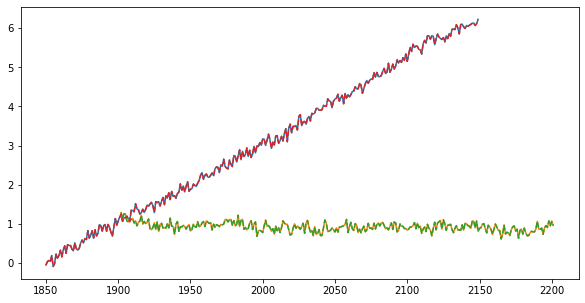

In [184]:
fig, ax = plt.subplots(1, 1, figsize=(10, 5))

# previous
ax.plot(df_GSAT["year"], df_GSAT["02Kpd"]-ref_GSAT)
ax.plot(df_GSAT["year"], df_GSAT["02Kpd-11"]-ref_GSAT)

# new 
ts_tas_11 = (ym_tas_11["tas"]*wa).sum(["lat", "lon"])
ts_tas = (ym_tas["tas"]*wa).sum(["lat", "lon"])
year =  ym_tas_11["time"].dt.year              

ax.plot(ym_tas_11["time"].dt.year, ts_tas_11-ref_GSAT, ls="--")
ax.plot(ym_tas["time"].dt.year, ts_tas-ref_GSAT, ls="--")

#### Question 2.8: 

Now we will analyse the behaviour of GSAT after emission-cessation.

* Plot each of the _02Kpd-XX_ runs relative to their first year.
* Comment on the overall evolution of each of these run (calculate the trend, the mean over temporal windows...).

**Help:** You can get inspiration from the calculation of the ZEC (Zero Emission Commitment) metric for each net-zero run and at various time horizons after emission cessation. This metric is introduced in the paper of [MacDougall et al. (2020)](https://bg.copernicus.org/articles/17/2987/2020/). ZEC$_t$ are defined relative to the year where emissions
cease (t0) and averaged over a 21-year window centered around year t, see the following Equation. We can also calculate the ZEC over the whole timeseries.

<img src="../figures/ZEC.png" width="300" style="display: block;"/>


#### Question 2.9:

We will now compare our results with another ramp-up simulation with a 10GtC/year forcing: flat10 protocol.

* Plot GSAT and GMCO2 following a 10GtC/yr forcing.
* Comment on the differences

**Help:** Data are store in ```./../data/CNRM-ESM2-2/e-driven/flat10/```


In [220]:
# load simulation outputs
df_co2s_flat10 = pd.read_csv("./../data/CNRM-ESM2-2/e-driven/flat10/dataframe_flat10_timeseries_yearly_co2s_Amon.csv")
df_tas_flat10 = pd.read_csv("./../data/CNRM-ESM2-2/e-driven/flat10/dataframe_flat10_timeseries_yearly_tas_Amon.csv")

Text(0.5, 1.0, 'b. GMCO2 in esm-piControl')

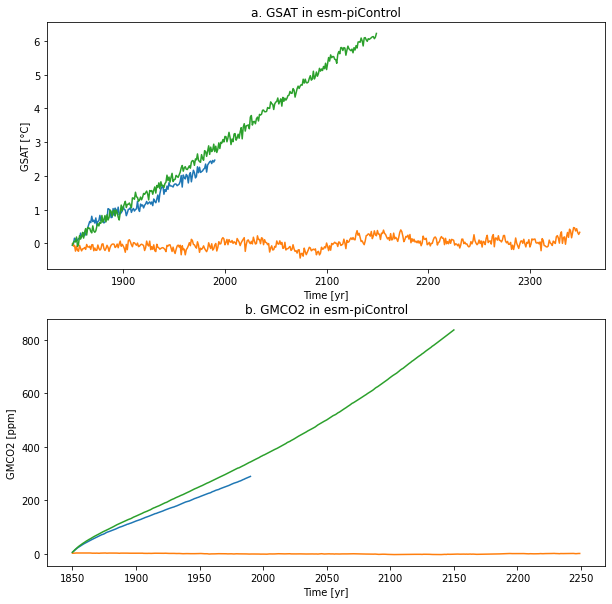

In [221]:
fig, axes = plt.subplots(2, 1, figsize=(10, 10))

ref_CO2 = df_CO2["esm-piControl"].mean()
ref_GSAT = df_GSAT["esm-piControl"].mean()

axes[0].plot(df_tas_flat10["year"], df_tas_flat10["flat10"]-ref_GSAT)
axes[1].plot(df_co2s_flat10["year"], df_co2s_flat10["flat10"]*(10**6)-ref_CO2)

axes[0].plot(df_GSAT["year"], df_GSAT["esm-piControl"]-ref_GSAT)
axes[1].plot(df_CO2["year"], df_CO2["esm-piControl"]-ref_CO2)

axes[0].plot(df_GSAT["year"], df_GSAT["02Kpd"]-ref_GSAT)
axes[1].plot(df_CO2["year"], df_CO2["02Kpd"]-ref_CO2)

axes[0].set_xlabel("Time [yr]")
axes[0].set_ylabel("GSAT [°C]")
axes[1].set_xlabel("Time [yr]")
axes[1].set_ylabel("GMCO2 [ppm]")

axes[0].set_title("a. GSAT in esm-piControl")
axes[1].set_title("b. GMCO2 in esm-piControl")

#### Question 2.10: 

Now, we will compare our result to the one of other climate models. The model that provided us with data are the following: 

<img src="./../figures/models.png" width="300" style="display: block;"/>

* _Plot GSAT and GMCO2 for each model_
* _Compare the different results_
* _Compare the ZEC_
* _Discuss on the TCRE of the different models_

**Help:** Data are stored in ```./../data/CNRM-ESM2-2/e-driven/tipmip/```

#### Question 2.11: 

* Conclude on this section

<a id="section-1"></a>
## 3. Investigation on the GSAT stabilization


We saw in the previous section the GSAT stabilizes after emission-cessation. This equilibration is linked to 2 processes: a cooling effect linked to CO$_2$ and a warming effect linked to the Ocean Heat Uptake (OHU). 

* On the one hand, studies have shown that the cooling effect is related to the continuous decrease in CO$_2$ concentration in the atmosphere (GMCO2) which in turn leads to a decrease in radiative forcing (RFCO2,[ MacDougall et al., 2020;](https://bg.copernicus.org/articles/17/2987/2020/)[ Palazzo-Corner et al., 2023)](https://www.frontiersin.org/journals/science/articles/10.3389/fsci.2023.1170744/full).
* On the other hand, the ocean continues to absorb heat from the atmosphere but this uptake decreases to eventually reach zero [(MacDougall et al., 2020;](https://bg.copernicus.org/articles/17/2987/2020/)[ Palazzo-Corner et al., 2023)](https://www.frontiersin.org/journals/science/articles/10.3389/fsci.2023.1170744/full).

These two opposit processes are summarized in the following figure:

<img src="./../figures/balance.png" width="600" style="display: block;"/>

In this section we aim to investigate these two processes in our model to validate the hypothesis.

#### Question 3.1: 

In the folder "data/CNRM-ESM2-2/e-driven/" multiple variables were pre-processed. You can load the following variables:

* tas : Near-Surface Air Temperature averaged globally (°C)
* co2s : Atmosphere CO2 averaged globally (ppm)
* hfds : Downward Heat Flux at Sea Water Surface integrated globally (W m$^2$)

In [232]:
# load variables
df_tas = pd.read_csv("../data/CNRM-ESM2-2/e-driven/dataframe/dataframe_02Kpd_timeseries_yearly_tas_Amon.csv")
df_hfds = pd.read_csv("./../data/CNRM-ESM2-2/e-driven/dataframe/dataframe_02Kpd_timeseries_yearly_hfds.csv")
df_co2s = pd.read_csv("./../data/CNRM-ESM2-2/e-driven/dataframe/dataframe_02Kpd_timeseries_yearly_co2s.csv")

In [233]:
# apply a rolling mean
df_tas_rm = df_tas.rolling(window=31, center = True, min_periods=31).mean()
df_hfds_rm = df_hfds.rolling(window=31, center = True, min_periods=31).mean()

#### Question 3.2: 

* Code a function to calculate the radiative forcing of CO$_2$ by using [Myrhe et al. (1998)](https://agupubs.onlinelibrary.wiley.com/) relationship:

<img src="./../figures/myrhe_relationship.png" width="300" style="display: block;"/>

* Calculate the radiative forcing of CO$_2$.

In [237]:
# radiative forcing : RF
def RF_calc(v) :
    index = np.where(~np.isnan(v))[0][0]
    return 5.35*np.log(v/v[index])

In [238]:
# apply RF function
df_RF = df_co2s.copy()
df_RF = df_RF.apply(RF_calc)
df_RF["year"] = df_co2s["year"].values

In [239]:
expe =   ["02Kpd",
          "02Kpd-11", 
          "02Kpd-15",  
          "02Kpd-20", 
          "02Kpd-25",
          "02Kpd-30", 
          "02Kpd-35",
          "02Kpd-40",
          "02Kpd-45", 
          "02Kpd-50"]

In [240]:
#%% List of colors
cmap = plt.cm.get_cmap("YlOrRd")
colors = [cmap(i) for i in np.linspace(0.3, 1, 9)]
colors_ext = [cmap(i) for i in np.linspace(0.3, 1, 9)]
cmap_discrete_ext = ListedColormap(colors_ext)

#### Question 3.3: 

* Plot on the same figure the 2 effects (cooling and warming) and the balance/imbalance between the two of them.

**Help:** You can see that som variable are very noisy. You can smooth them with the lowess function : lowess(data, time, return_sorted=False, frac=0.08)

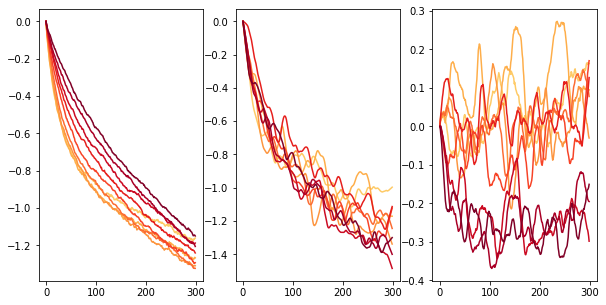

In [241]:
fig, axes = plt.subplots(1, 3, figsize=(10, 5))

for e in range(1,len(expe)):
    time = np.arange(0,300,1)
    ts = df_RF[expe[e]]
    ts_short = ts[np.where(~np.isnan(ts))[0]]
    axes[0].plot(time, ts_short - ts_short.values[0], color=colors_ext[e-1])
    
for e in range(1,len(expe)):
    ts = df_hfds[expe[e]]
    ts_short = ts[np.where(~np.isnan(ts))[0]]
    ts_lowess = lowess(ts_short, time, return_sorted=False, frac=0.08)
    axes[1].plot(time, ts_lowess - ts_lowess[0], color=colors_ext[e-1])
    
        
for e in range(1,len(expe)):
    time = np.arange(0,300,1)
    ts = df_RF[expe[e]]
    ts_short = ts[np.where(~np.isnan(ts))[0]]
    
    ts2 = df_hfds[expe[e]]
    ts2_short = ts2[np.where(~np.isnan(ts2))[0]]
    ts2_lowess = lowess(ts2_short, time, return_sorted=False, frac=0.08)
    
    substraction = (ts2_lowess - ts2_lowess[0]) - (ts_short - ts_short.values[0]) 
    axes[2].plot(time, substraction, color=colors_ext[e-1])
    

#### Question 3.4: 
 
* Discuss the balance/imbalance results with regard to the ZEC data you calculate before.

<a id="section-1"></a>
## 4. Check other variables and discuss the equilibrum

This section is more exploratory. We saw that GSAT stabilizes rather well (at least for 02Kpd-11 to 02Kpd-40 included). However, this behaviour is not necessarily the case for other variable of the climate system.

We pre-processed some variables from which you can investigate the behaviour and discuss.


#### Question 4.1: 

Check other variables and discuss the equilibrum.

__Helps:__ In the folder "data/CNRM-ESM2-2/e-driven" multiple variables were pre-processed. You can load them and check.

In [245]:
# load variables
df_tos = pd.read_csv("./../data/CNRM-ESM2-2/e-driven/dataframe/dataframe_02Kpd_timeseries_yearly_tos_Omon.csv")

In [246]:
#%% Expérience qui t'intéresse ici dans "expe"
expe = ["esm-piControl",
        "02Kpd",
        "02Kpd-11",
        "02Kpd-15",
        "02Kpd-20",
        "02Kpd-25",
        "02Kpd-30",
        "02Kpd-35",
        "02Kpd-40",
        "02Kpd-45",
        "02Kpd-50",
        "esm-up2p0-gwl2p0-50y-dn2p0",
        "esm-up2p0-gwl4p0-50y-dn2p0",
        "esm-up2p0-gwl4p0-50y-dn2p0-gwl2p0"]

In [247]:
#%% Colors for each of run of "expe"
nb = 9

cmap = plt.cm.get_cmap("YlOrRd")
colors = [cmap(i) for i in np.linspace(0.3, 1, nb)]; print(len(colors))
colors.insert(0,(1,0,0,1))
colors.append((85/255,153/255,1,1))
colors.append((0,0,1,1))
colors.append((0,128/255,0,1))
colors.insert(0,(0,0,0,1))

9


In [248]:
#%% Load variable csv files
DIR = "/cnrm/est/USERS/bosserti/Roland/DATA/"

df_tos = pd.read_csv("./../data/CNRM-ESM2-2/e-driven/dataframe/dataframe_02Kpd_timeseries_yearly_tos_Omon.csv")
ref_tos =  np.nanmean(df_tos["esm-piControl"].values[:100])
std_tos = np.std(df_tos["esm-piControl"].values[:100])

df_heatc = pd.read_csv("./../data/CNRM-ESM2-2/e-driven/dataframe/dataframe_02Kpd_timeseries_yearly_heatc_HOMOImon.csv")
ref_heatc =  np.nanmean(df_heatc["esm-piControl"].values[:100])
std_heatc = np.std(df_heatc["esm-piControl"].values[:100])

df_msftyz = pd.read_csv("./../data/CNRM-ESM2-2/e-driven/dataframe/dataframe_02Kpd_timeseries_yearly_msftyz_Omon.csv")
ref_msftyz =  np.nanmean(df_msftyz["esm-piControl"].values[:100])
std_msftyz = np.std(df_msftyz["esm-piControl"].values[:100])

df_intdic = pd.read_csv("./../data/CNRM-ESM2-2/e-driven/dataframe/dataframe_02Kpd_timeseries_yearly_intdic_Omon.csv")
ref_intdic =  np.nanmean(df_intdic["esm-piControl"].values[:100])
std_intdic = np.std(df_intdic["esm-piControl"].values[:100])

df_intpp = pd.read_csv("./../data/CNRM-ESM2-2/e-driven/dataframe/dataframe_02Kpd_timeseries_yearly_intpp_Omon.csv")
ref_intpp =  np.nanmean(df_intpp["esm-piControl"].values[:100])
std_intpp = np.std(df_intpp["esm-piControl"].values[:100])

df_phs = pd.read_csv("./../data/CNRM-ESM2-2/e-driven/dataframe/dataframe_02Kpd_timeseries_yearly_phs_Omon.csv")
df_phs = df_phs.interpolate(method="linear", limit_area="inside")
ref_phs =  np.nanmean(df_phs["esm-piControl"].values[:100])
std_phs = np.std(df_phs["esm-piControl"].values[:100])

df_talks = pd.read_csv("./../data/CNRM-ESM2-2/e-driven/dataframe/dataframe_02Kpd_timeseries_yearly_talks_Omon.csv")
df_talks = df_talks.interpolate(method="linear", limit_area="inside")
ref_talks =  np.nanmean(df_talks["esm-piControl"].values[:100])
std_talks = np.std(df_talks["esm-piControl"].values[:100])

In [249]:
# %% Apply rolling mean
df_tos_rm = df_tos.rolling(window=31, center = True, min_periods=31).mean()
df_heatc_rm = df_heatc.rolling(window=31, center = True, min_periods=31).mean()
df_msftyz_rm = df_msftyz.rolling(window=31, center = True, min_periods=31).mean()
df_intdic_rm = df_intdic.rolling(window=31, center = True, min_periods=31).mean()
df_intpp_rm = df_intpp.rolling(window=31, center = True, min_periods=31).mean()
df_phs_rm = df_phs.rolling(window=31, center = True, min_periods=31).apply(np.nanmean)
df_talks_rm = df_talks.rolling(window=31, center = True, min_periods=31).apply(np.nanmean)

In [250]:
#%% Colors for legend
nb = 9
cmap = plt.cm.get_cmap("YlOrRd")
colors_ext = [cmap(i) for i in np.linspace(0.3, 1, nb)]; print(len(colors_ext))
colors_ext.append((1,1,1,1))
colors_ext.append((1,0,0,1))
colors_ext.append((1,1,1,1))
colors_ext.append((85/255,153/255,1,1))
colors_ext.append((0,0,1,1))
colors_ext.append((0,128/255,0,1))
colors_ext.append((1,1,1,1))
colors_ext.append((0,0,0,1))
cmap_discrete_ext = ListedColormap(colors_ext)
expe_ext_long = ["02Kpd-11", "02Kpd-15",   "02Kpd-20", "02Kpd-25", "02Kpd-30", "02Kpd-35", "02Kpd-40", "02Kpd-45", "02Kpd-50", "", "02Kpd", "","02Kpd-20-down", "02Kpd-40-down", "02Kpd-40-down-20", "", "esm-piControl"]

9


Text(0.0, 1.0, 'tos')

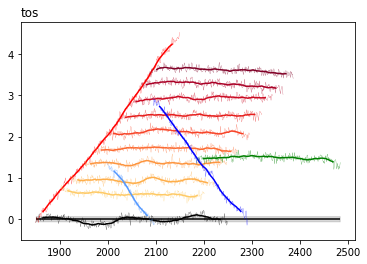

In [252]:
#%%
fig, ax = plt.subplots(1, 1)
var = "tos"
df = globals()["df_"+var]
df_rm = globals()["df_"+var+"_rm"]
ref = globals()["ref_"+var]
std = globals()["std_"+var]

ax.hlines(0, 1850, 2484, color="k")
ax.fill_between(np.arange(1850,2484), -std, std, color="grey", alpha=0.3)
for e in range(0,len(expe)):
    ax.plot(df["year"], df[expe[e]]-ref, color=colors[e], lw=0.2)  
    ax.plot(df_rm["year"], df_rm[expe[e]]-ref, color=colors[e], lw=1.5)  
#==================================================
# Parameters
#==================================================
ax.set_title(var, loc='left')

<a id="section-1"></a>
## 5. Conclusion

Give a summary to this TP of what you have understood, discovered. Both in terms of technical tools and science.